**Limpieza y unión de Bases de Datos BMC Códigos-Solicitud**

---
1.   Códigos
2.   Datos solicitados
3.   Intersección



# **Índice de Complejidad Económica**

Computatar y entender el Ímdice de Complejidad Económica


In [1]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
# Ignorar advertencias futuras para mantener la salida limpia
warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
# Acceso a las bases de datos de Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# Ruta al archivo de Excel en Google Drive
BASE_DATOS16_25 = '/content/drive/MyDrive/BMC-Datalab/Muestra_datos_MCP_MERCOP_2016-2025.xlsx'

# Leer el archivo Excel en un DataFrame de pandas
BMC_trade_df = pd.read_excel(BASE_DATOS16_25)

# Mostrar las primeras filas del DataFrame
print("Primeras 5 filas de los datos 'BMC_DATA.xlsx' desde Google Drive:")
print(BMC_trade_df.head())

Primeras 5 filas de los datos 'BMC_DATA.xlsx' desde Google Drive:
  cantidad ciudad_ubicacion departamento_ubicacion  \
0        1      BOGOTA D.C.              BOGOTÁ DC   
1   350133         RIOHACHA             LA GUAJIRA   
2        1      BOGOTA D.C.              BOGOTÁ DC   
3        1      BOGOTA D.C.              BOGOTÁ DC   
4   200000           CERETE                CORDOBA   

     Clasificación_subyacente  \
0                       Otros   
1  Suministro de alimentación   
2                  Dotaciones   
3                  Vigilancia   
4                         NaN   

                      desc_subyacente_caracteristica  \
0  ELEMENTOS DE PAPELERIA - SC - UNIDAD - EMPACAD...   
1  SUMINISTRO DE LECHE ENTERA - LECHE ENTERA - LI...   
2  UNIFORMES - camiseta camisa y pantalon carcel ...   
3  Servicio de vigilancia y medios tecnologicos -...   
4  FIBRA DE ALGODON - 142-GRADO SLM - KILOGRAMO -...   

                                desc_subyacente desc_unidad  dias_plazo  

In [7]:
xl = pd.ExcelFile(BASE_DATOS16_25)
sheet_names = xl.sheet_names

print("Hojas encontradas en 'BMC.xlsx':")
for sheet in sheet_names:
    print(f"- {sheet}")

# Ahora, cargamos cada hoja en un DataFrame separado
sheets_data = {}
for sheet_name in sheet_names:
    print(f"\nCargando datos de la hoja: '{sheet_name}'")
    sheets_data[sheet_name] = pd.read_excel(BASE_DATOS16_25, sheet_name=sheet_name)
    print(f"Primeras 5 filas de '{sheet_name}':")
    display(sheets_data[sheet_name].head())

Hojas encontradas en 'BMC.xlsx':
- Export
- Div_Ubicuidad

Cargando datos de la hoja: 'Export'
Primeras 5 filas de 'Export':


,cantidad,ciudad_ubicacion,departamento_ubicacion,Clasificación_subyacente,desc_subyacente_caracteristica,desc_subyacente,desc_unidad,dias_plazo,fecha_operacion,fecha_pago,entidad_compra,entidad_venta,Clasificacion_EMIS_proveedor,precio_unitario,valor_negocio,cantidad_presupuesto,Negocio,valor_presupuesto
0,1,BOGOTA D.C.,BOGOTÁ DC,Otros,ELEMENTOS DE PAPELERIA - SC - UNIDAD - EMPACAD...,ELEMENTOS DE PAPELERIA,UNIDAD,146.0,2016-01-05,2016-05-31,13.0,506.0,NaN,3.500911e+07,3.500911e+07,NaN,MCP,NaN
1,350133,RIOHACHA,LA GUAJIRA,Suministro de alimentación,SUMINISTRO DE LECHE ENTERA - LECHE ENTERA - LI...,SUMINISTRO DE LECHE ENTERA,LITRO,93.0,2016-01-05,2016-04-08,233.0,38.0,Grande,2.600000e+03,9.103458e+08,NaN,MCP,NaN
2,1,BOGOTA D.C.,BOGOTÁ DC,Dotaciones,UNIFORMES - camiseta camisa y pantalon carcel ...,UNIFORMES,UNIDAD,119.0,2016-01-08,2016-05-07,17.0,416.0,Mediana,1.765520e+08,1.765520e+08,NaN,MCP,NaN
3,1,BOGOTA D.C.,BOGOTÁ DC,Vigilancia,Servicio de vigilancia y medios tecnologicos -...,Servicio de vigilancia y medios tecnologicos,UNIDAD,226.0,2016-01-15,2016-08-31,156.0,1169.0,Grande,2.127686e+09,2.127686e+09,NaN,MCP,NaN
4,200000,CERETE,CORDOBA,NaN,FIBRA DE ALGODON - 142-GRADO SLM - KILOGRAMO -...,FIBRA DE ALGODON,KILOGRAMO,48.0,2016-01-18,2016-04-23,2.0,59.0,NaN,4.404209e+03,8.808418e+08,NaN,MERCOP,NaN



Cargando datos de la hoja: 'Div_Ubicuidad'
Primeras 5 filas de 'Div_Ubicuidad':


,Variable,Valor,Unnamed: 2,Unnamed: 3,Año,Departamento,Diversificación,ECI,Fitness,fecha_pago (primera),...,fecha_pago (primera).1,fecha_pago (última).1,Unnamed: 18,Unnamed: 19,departamento_ubicacion,desc_subyacente,fecha_pago,valor_negocio,Diversificación (depto),Ubicuidad (producto)
0,Fecha de exportación,2026-11-01 12:40,NaN,NaN,Export,BOGOTÁ DC,240.0,5.054745,3.200000e+01,2016-03-22,...,2018-10-05,2023-03-29,NaN,NaN,BOGOTÁ DC,ELEMENTOS DE PAPELERIA,2016-05-31,3.500911e+07,240.0,5.0
1,Año de los datos (matriz),Export,NaN,NaN,Export,CUNDINAMARCA,132.0,-0.873324,1.701447e-06,2016-04-10,...,2018-10-05,2026-10-01,NaN,NaN,LA GUAJIRA,SUMINISTRO DE LECHE ENTERA,2016-04-08,9.103458e+08,7.0,1.0
2,fecha_pago mínima,2016-03-22,NaN,NaN,Export,ANTIOQUIA,69.0,0.000209,5.469940e-17,2016-08-29,...,2016-08-24,2028-05-01,NaN,NaN,BOGOTÁ DC,UNIFORMES,2016-05-07,1.765520e+08,240.0,1.0
3,fecha_pago máxima,2032-10-28,NaN,NaN,Export,VALLE DEL CAUCA,67.0,0.305869,7.441395e-17,2016-08-29,...,2016-10-09,2026-03-11,NaN,NaN,BOGOTÁ DC,Servicio de vigilancia y medios tecnologicos,2016-08-31,2.127686e+09,240.0,9.0
4,Archivo fuente (BASE_DATOS16_25),/content/drive/MyDrive/Muestra_datos_MCP_MERCO...,NaN,NaN,Export,BOLIVAR,55.0,0.337656,8.874468e-19,2016-08-29,...,2018-10-08,2026-03-30,NaN,NaN,CORDOBA,FIBRA DE ALGODON,2016-04-23,8.808418e+08,41.0,5.0


In [8]:
mcp_matrices_by_year = {}

for year, df_year in sheets_data.items():
    print(f"\nProcesando datos para el año: {year}")
    print(f"Columnas en la hoja '{year}': {df_year.columns.tolist()}") # Línea de depuración

    # Seleccionar columnas relevantes: Departamento, Descripción de Actividad y Valor del Negocio
    # Se asume una estructura consistente basada en el archivo de Excel
    try:
        df_trade = df_year[['departamento_ubicacion', 'desc_subyacente', 'valor_negocio']].copy()
    except KeyError as e:
        print(f"Error: Falta una columna esperada en la hoja '{year}'. Por favor verifica los nombres. Error: {e}")
        continue

    # Agregar valores de comercio: sumar el 'valor_negocio' para cada par (Departamento, Producto)
    # Crear una tabla dinámica (pivot table) donde las filas son los departamentos y las columnas son los productos
    country_partner_trade = df_trade.pivot_table(
        index='departamento_ubicacion',
        columns='desc_subyacente',
        values='valor_negocio',
        fill_value=0 # Llenar valores nulos (sin comercio) con 0
    )

    # Asegurar que todas las columnas sean numéricas para los cálculos y rellenar NaNs restantes con 0
    country_partner_trade = country_partner_trade.apply(pd.to_numeric, errors='coerce').fillna(0)

    # Calcular la Ventaja Comparativa Revelada (RCA)
    # 1. Exportaciones totales de cada departamento (suma de filas)
    trade_c = country_partner_trade.sum(axis=1)

    # 2. Demanda total para cada producto (suma de columnas)
    trade_p = country_partner_trade.sum(axis=0)

    # 3. Comercio total del año
    total_trade = country_partner_trade.sum().sum()

    # Calcular el numerador de la RCA: participación del producto 'p' en las exportaciones totales del departamento 'c'
    # Manejar casos donde las exportaciones totales de un departamento sean cero para evitar divisiones por cero
    rca_numerator = country_partner_trade.div(trade_c, axis=0)

    # Calcular el denominador de la RCA: participación del producto 'p' en el comercio total general
    rca_denominator = trade_p.div(total_trade, axis=0)

    # Calcular la matriz RCA final mediante la división elemento por elemento
    rca_matrix = rca_numerator.div(rca_denominator, axis=1)

    # Crear la matriz binaria Mcp (1 si RCA >= 1, de lo contrario 0)
    # Rellenar con 0 los valores NaN resultantes de divisiones por cero
    mcp_matrix = (rca_matrix >= 1).astype(int).fillna(0)

    mcp_matrices_by_year[year] = mcp_matrix
    print(f"Matriz Mcp creada para {year} con dimensiones: {mcp_matrix.shape}")
    print(f"Primeras 5 filas de Mcp para {year}:")
    display(mcp_matrix.head())

# Mostrar resumen de las matrices generadas
print("\nResumen de matrices Mcp generadas:")
for year, mcp_mat in mcp_matrices_by_year.items():
    print(f"Año {year}: Dimensiones {mcp_mat.shape}, Cantidad de 1s (conexiones): {mcp_mat.sum().sum()}")


Procesando datos para el año: Export
Columnas en la hoja 'Export': ['cantidad', 'ciudad_ubicacion', 'departamento_ubicacion', 'Clasificación_subyacente', 'desc_subyacente_caracteristica', 'desc_subyacente', 'desc_unidad', 'dias_plazo', 'fecha_operacion', 'fecha_pago', 'entidad_compra', 'entidad_venta', 'Clasificacion_EMIS_proveedor', 'precio_unitario', 'valor_negocio', 'cantidad_presupuesto', 'Negocio', 'valor_presupuesto']
Matriz Mcp creada para Export con dimensiones: (32, 516)
Primeras 5 filas de Mcp para Export:


desc_subyacente,ABARROTES POR LOTE,ACEITE CRUDO DE PALMA,ACEITE REFINADO DE OLIVA,ACEITE VEGETAL DE PALMA,ACEITE VEGETAL POR LOTE,ACEITE VIRGEN,ADQUISICION CONFIGURACION E IMPLEMENTACION DE SI,AERONAVES NO TRIPULADAS,AGROINSUMOS POR LOTE,AGUA DE PANELA CON QUESO,...,VESTUARIO Y CALZADO POR LOTE,VIDEOBEAM,VIDRIO,VINAGRE BLANCO,VINAGRE BLANCO POR LOTE,VIVERES Y ABARROTES POR LOTE,Velcro,YOGURT,YUCA,pegante
departamento_ubicacion,,,,,,,,,,,,,,,,,,,,,
AMAZONAS,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ANTIOQUIA,0,0,0,0,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ARAUCA,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ATLANTICO,0,0,0,1,0,1,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
BOGOTÁ DC,1,0,0,0,0,0,1,1,0,0,...,1,1,1,0,0,1,1,1,0,1



Procesando datos para el año: Div_Ubicuidad
Columnas en la hoja 'Div_Ubicuidad': ['Variable', 'Valor', 'Unnamed: 2', 'Unnamed: 3', 'Año', 'Departamento', 'Diversificación', 'ECI', 'Fitness', 'fecha_pago (primera)', 'fecha_pago (última)', 'Unnamed: 11', 'Año.1', 'Producto', 'Ubicuidad', 'Complejidad', 'fecha_pago (primera).1', 'fecha_pago (última).1', 'Unnamed: 18', 'Unnamed: 19', 'departamento_ubicacion', 'desc_subyacente', 'fecha_pago', 'valor_negocio', 'Diversificación (depto)', 'Ubicuidad (producto)']
Matriz Mcp creada para Div_Ubicuidad con dimensiones: (32, 516)
Primeras 5 filas de Mcp para Div_Ubicuidad:


desc_subyacente,ABARROTES POR LOTE,ACEITE CRUDO DE PALMA,ACEITE REFINADO DE OLIVA,ACEITE VEGETAL DE PALMA,ACEITE VEGETAL POR LOTE,ACEITE VIRGEN,ADQUISICION CONFIGURACION E IMPLEMENTACION DE SI,AERONAVES NO TRIPULADAS,AGROINSUMOS POR LOTE,AGUA DE PANELA CON QUESO,...,VESTUARIO Y CALZADO POR LOTE,VIDEOBEAM,VIDRIO,VINAGRE BLANCO,VINAGRE BLANCO POR LOTE,VIVERES Y ABARROTES POR LOTE,Velcro,YOGURT,YUCA,pegante
departamento_ubicacion,,,,,,,,,,,,,,,,,,,,,
AMAZONAS,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ANTIOQUIA,0,0,0,0,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ARAUCA,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ATLANTICO,0,0,0,1,0,1,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
BOGOTÁ DC,1,0,0,0,0,0,1,1,0,0,...,1,1,1,0,0,1,1,1,0,1



Resumen de matrices Mcp generadas:
Año Export: Dimensiones (32, 516), Cantidad de 1s (conexiones): 1220
Año Div_Ubicuidad: Dimensiones (32, 516), Cantidad de 1s (conexiones): 1220


In [ ]:
# Definir matriz Mcp teórica, que conecta países imaginarios con actividades económicas.

#countries = ['Vale of Arryn', 'The North', 'The Riverlands', 'Dorne', 'The Stormland', 'The Westerlands', 'The Reach']
#activities = [f'P{j}' for j in range(9)]

# Mcp = np.array([[1, 0, 1, 0, 1, 1, 0, 0, 1],
#            [0, 1, 1, 0, 0, 1, 1, 0, 0],
#            [0, 1, 0, 1, 1, 0, 0, 0, 0],
#            [1, 0, 1, 0, 0, 0, 0, 0, 0],
#            [0, 0, 0, 0, 0, 1, 1, 1, 1],
#            [0, 1, 1, 0, 1, 0, 1, 1, 1],
#            [1, 1, 1, 1, 1, 0, 1, 0, 1]])
#R, C = Mcp.shape

Mcp = mcp_matrix.values
countries = mcp_matrix.index.tolist()
activities = mcp_matrix.columns.tolist()
R, C = Mcp.shape

# Diversificación y ubicuidad como arreglos numpy
diversification = Mcp.sum(axis=1)
ubiquity = Mcp.sum(axis=0)

*RCA (Ventaja Comparativa Revelada) y RAA son matrices de variables endógenas para calcular Mcp*

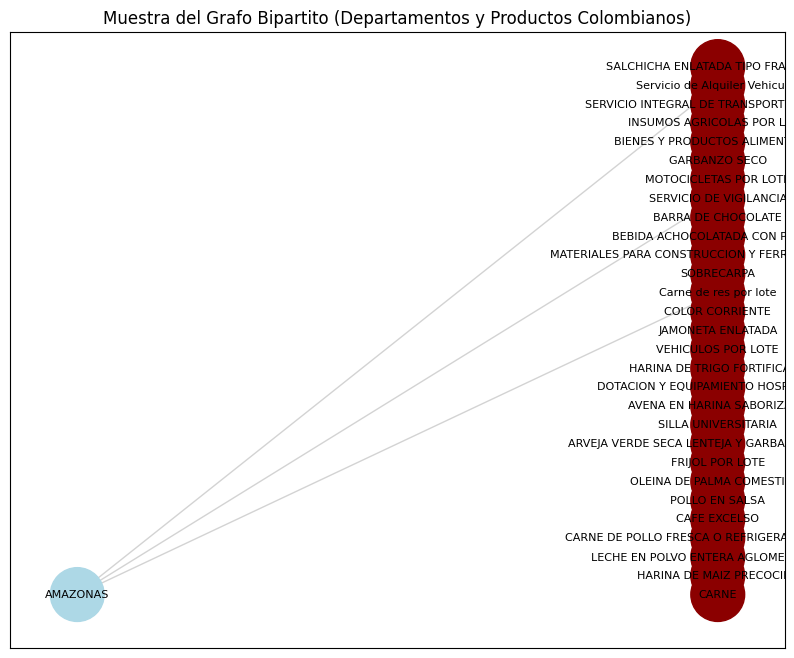

In [9]:
# Extraemos los nombres de departamentos y productos desde la matriz real calculada
departamento_ubicacion = mcp_matrix.index.tolist()
desc_subyacente = mcp_matrix.columns.tolist()
Mcp_values = mcp_matrix.values
R, C = Mcp_values.shape

G = nx.Graph()

# Agregar nodos de los departamentos (grupo bipartito 0)
G.add_nodes_from(departamento_ubicacion, bipartite=0)

# Agregar nodos de los productos (grupo bipartito 1)
G.add_nodes_from(desc_subyacente, bipartite=1)

# Agregar aristas donde el valor en la matriz de adyacencia sea 1
for i in range(R):
    for j in range(C):
        if Mcp_values[i, j] == 1:
            G.add_edge(departamento_ubicacion[i], desc_subyacente[j])

# Graficar un subconjunto de la red para que sea legible (ya que hay 516 productos)
# Filtramos para graficar solo los nodos conectados a los primeros 3 departamentos
sub_nodes = departamento_ubicacion[:3] + [n for n in G.neighbors(departamento_ubicacion[0])] + [n for n in G.neighbors(departamento_ubicacion[1])] + [n for n in G.neighbors(departamento_ubicacion[2])]
sub_nodes = list(set(sub_nodes))[:30] # Limitamos a 30 nodos para una mejor visualización
sub_G = G.subgraph(sub_nodes)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
sub_departments = [n for n in sub_nodes if n in departamento_ubicacion]
pos = nx.bipartite_layout(sub_G, sub_departments)

node_colors = ['lightblue' if node in departamento_ubicacion else 'darkred' for node in sub_G.nodes()]

nx.draw_networkx(sub_G, pos, edge_color='lightgray', node_color=node_colors, node_size=1500, font_size=8, font_color='black', ax=ax)

plt.title("Muestra del Grafo Bipartito (Departamentos y Productos Colombianos)")
plt.show()

**1.1. Proporcionar estadísticas clave sobre los países, incluyendo medidas de diversificación económica y especialización.**
  
* **Estadísticas Clave:**
  Ajuste del PIB (GDP-Fitness), Ajuste de Sector (Sector Fitness), pronóstico sectorial, ajuste tecnológico regional.
* **Diversificación:**
  a. Densidad S (página 86) y matriz de adyacencia B (página 86)
  b. Relación basada en la co-ubicación
  c. Análisis Multidimensional (página 89)
* **Especialización:**
  a. Construcción de matrices de actividad ponderadas - Matriz de Especialización, Matriz X



---



## 1. Estadisticas descriptivas ##
---

### Diversificación *primer orden aproximación a la complejidad*

In [10]:
# Calcular la diversificación real por departamento usando mcp_matrix
diversification = mcp_matrix.sum(axis=1)
print("Diversificación por Departamento:")
print(diversification)

# Ordenar los departamentos de mayor a menor diversificación
order_departments_Di = np.argsort(diversification)[::-1]
departamentos_ordenados = [mcp_matrix.index[i] for i in order_departments_Di]
print("\nDepartamentos ordenados por su diversificación de mayor a menor:")
print(departamentos_ordenados)

Diversificación por Departamento:
departamento_ubicacion
AMAZONAS                9
ANTIOQUIA              69
ARAUCA                 38
ATLANTICO              50
BOGOTÁ DC             240
BOLIVAR                55
BOYACA                 10
CALDAS                 13
CAQUETA                48
CASANARE               31
CAUCA                   7
CESAR                  25
CHOCO                  25
CORDOBA                41
CUNDINAMARCA          132
GUAVIARE               16
HUILA                  38
LA GUAJIRA              7
MAGDALENA               4
META                   53
NARIÑO                 30
NORTE DE SANTANDER     25
PUTUMAYO               42
QUINDIO                 8
RISARALDA               9
SAN ANDRES              6
SANTANDER              28
SUCRE                  42
TOLIMA                 50
VALLE DEL CAUCA        67
VAUPES                  1
VICHADA                 1
dtype: int64

Departamentos ordenados por su diversificación de mayor a menor:
['BOGOTÁ DC', 'CUNDINAMARCA', 'A

**1.2. Analizar la ubicuidad de los productos y actividades.**

*   Donde Up = ΣcMc,p es la ubicuidad de la actividad p
...
*   Describir los resultados

In [11]:
# Calcular la ubicuidad real por producto usando mcp_matrix
ubiquity = mcp_matrix.sum(axis=0)
print("Estadísticas de Ubicuidad de los Productos:")
print(ubiquity.describe())

# Ordenar los productos de mayor a menor ubicuidad
order_products_Ub = np.argsort(ubiquity)[::-1]
productos_ordenados = [mcp_matrix.columns[i] for i in order_products_Ub]

print("\nTop 50 productos más ubicuos (producidos por más departamentos con ventaja comparativa):")
for prod in productos_ordenados[:50]:
    print(f"- {prod}: {ubiquity[prod]} departamentos")

Estadísticas de Ubicuidad de los Productos:
count    516.000000
mean       2.364341
std        2.626787
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       16.000000
dtype: float64

Top 50 productos más ubicuos (producidos por más departamentos con ventaja comparativa):
- Carne de res por lote: 16 departamentos
- Carne de cerdo por lote: 14 departamentos
- Carne de pollo por lote: 13 departamentos
- CALDO DE GALLINA: 13 departamentos
- SERVICIO: 13 departamentos
- AZUCAR BLANCO: 12 departamentos
- HARINA DE MAIZ PRECOCIDA: 12 departamentos
- PASTA ALIMENTICIA TIPO SECO: 12 departamentos
- SERVICIO DE VIGILANCIA: 12 departamentos
- ARROZ BLANCO NACIONAL EN BOLSA DE POLIETILENO: 12 departamentos
- MAYONESA: 11 departamentos
- JAMONETA ENLATADA: 11 departamentos
- SERVICIO DE SUMINISTRO Y ADQUISICION DE ALIMENTOS: 11 departamentos
- ARVEJA VERDE SECA: 11 departamentos
- BARRA DE CHOCOLATE: 11 departamentos
- PROGRAMA DE ALIMENTACION ESCOLAR: 11 depart

In [12]:
# 2. Foundation of Economic Complexity (Ubiquity); Fundamentos de la Complejidad Económica (ubicuidad)

# Usamos la matriz mcp_matrix real que ya fue calculada previamente
# Multiplicamos la matriz binaria por la ubicuidad de los productos y promediamos
ubiquity_measure = (
    mcp_matrix.values * ubiquity.values
).sum(axis=1) / diversification.values

# Paso E: Results in DataFrame for Plot; Resultados en el DataFrame para el gráfico
df_results = pd.DataFrame(
    {
        "departments": mcp_matrix.index,
        "diversification": diversification.values,
        "ubiquity_Measure": ubiquity_measure,
    }
).dropna()  # Eliminamos filas si algún departamento quedó con diversificación 0

# 3. GENERATE SCATTER PLOT; Generar Gráfico de Dispersión (Plotly)

fig = px.scatter(
    df_results,
    x="diversification",
    y="ubiquity_Measure",
    text="departments",  # Muestra el nombre del departamento al lado del punto
    hover_name="departments",  # Muestra el nombre al pasar el cursor
    title="Relación entre Diversificación y Ubicuidad",
    labels={
        "diversification": "Diversification",
        "ubiquity_Measure": "Average Ubiquity of Exports",
    },
    template="plotly_white",
)

# Ajustes estéticos para que el texto no se amontone
fig.update_traces(textposition="top center", marker=dict(size=12, color="green"))

# Mostrar gráfico
fig.show()

*La Diversificación es equivalente a sumar filas en la matriz binaria Mc(i)p(i), la Ubicuidad equivale a sumar columnas.*

### Método de Reflexiones

In [13]:
# Función para calcular un paso de kc(N+1) y kp(N+1) dada la matriz Mcp y los vectores previos kc(N) y kp(N)

def OneStep(Mcp, kc, kp):
    diversification = Mcp.sum(axis=1)
    ubiquity = Mcp.sum(axis=0)

    kc1 = Mcp.dot(kp) / diversification
    kp1 = Mcp.transpose().dot(kc) / ubiquity

    return kc1, kp1


# Función para inicializar kc(0) y kp(0), iterar el Método de Reflexiones N veces y normalizar el resultado
def MethodOfReflections(Mcp, max_iterations=10):
    ubiquity = np.sum(Mcp, axis=0)
    diversification = np.sum(Mcp, axis=1)

    # Definir las condiciones iniciales
    kc = diversification / diversification.sum()
    kp = ubiquity / ubiquity.sum()

    for iteration in range(max_iterations):
        kc, kp = OneStep(Mcp, kc, kp)

    # Retornar los vectores normalizados (puntuación Z)
    return (kc - kc.mean()) / kc.std(), (kp - kp.mean()) / kp.std()

In [ ]:
# Calcular un paso del método de reflexiones, partiendo de los valores de diversificación y ubicuidad

kc, kp = OneStep(Mcp, diversification, ubiquity)
print("Resultado del primer paso para kc:")
print(kc)

Resultado del primer paso para kc:
[ 9.          3.94202899  7.18421053  6.58        1.47083333  4.74545455
  5.9         7.53846154  7.33333333  7.96774194 10.42857143  8.28
  8.24        6.95121951  3.09090909  8.75        8.18421053  6.
  9.25        6.79245283  8.1         8.72        8.21428571  9.375
  7.77777778  7.66666667  7.28571429  6.92857143  4.08        4.92537313
  8.         10.        ]


---

# 2. Medidas de Complejidad Económica y Fitness

---

*   2.1. Calcular y comparar el Índice de Complejidad Económica (ECI) y el Fitness para los países/departamentos.

*   2.2. Calcular el Índice de Complejidad del Producto (PCI) y la Complejidad de las Actividades.

In [16]:
# Calcular el ECI (Índice de Complejidad Económica) con el Método de Reflexiones para cada año en mcp_matrices_by_year
for year, mcp_mat in mcp_matrices_by_year.items():
    print(f"\n=== Análisis de Complejidad Económica (ECI) para el año/hoja: {year} ===")

    # Convertir la matriz de DataFrame a numpy
    M_numpy = mcp_mat.values
    depto_list = mcp_mat.index.tolist()

    # Calcular ECI usando el Método de Reflexiones (el retorno kc es el primer elemento de la tupla)
    kc, _ = MethodOfReflections(M_numpy, max_iterations=10)

    print("Valores de ECI calculados y normalizados (Z-score):")
    for depto, val in zip(depto_list, kc):
        print(f"- {depto}: {val:.4f}")

    # Imprimir el orden jerárquico de los departamentos de mayor a menor complejidad
    order_deptos = np.argsort(kc)[::-1]
    print("\nOrden de los departamentos según su ECI (de mayor a menor complejo):")
    for rank, idx in enumerate(order_deptos, 1):
        print(f"{rank}. {depto_list[idx]} (ECI: {kc[idx]:.4f})")


=== Análisis de Complejidad Económica (ECI) para el año/hoja: Export ===
Valores de ECI calculados y normalizados (Z-score):
- AMAZONAS: 0.1427
- ANTIOQUIA: -0.0385
- ARAUCA: -0.4582
- ATLANTICO: -0.2317
- BOGOTÁ DC: 5.1717
- BOLIVAR: 0.3577
- BOYACA: 0.2980
- CALDAS: 0.4019
- CAQUETA: -0.4935
- CASANARE: -0.5254
- CAUCA: -0.0808
- CESAR: -0.5848
- CHOCO: -0.6062
- CORDOBA: -0.4408
- CUNDINAMARCA: -0.0290
- GUAVIARE: -0.5680
- HUILA: -0.2750
- LA GUAJIRA: 0.0054
- MAGDALENA: 0.2586
- META: -0.3450
- NARIÑO: -0.5944
- NORTE DE SANTANDER: -0.5999
- PUTUMAYO: -0.6059
- QUINDIO: 0.0665
- RISARALDA: -0.2109
- SAN ANDRES: 0.2252
- SANTANDER: -0.3174
- SUCRE: -0.4467
- TOLIMA: 0.8624
- VALLE DEL CAUCA: 0.3321
- VAUPES: -0.2446
- VICHADA: -0.4251

Orden de los departamentos según su ECI (de mayor a menor complejo):
1. BOGOTÁ DC (ECI: 5.1717)
2. TOLIMA (ECI: 0.8624)
3. CALDAS (ECI: 0.4019)
4. BOLIVAR (ECI: 0.3577)
5. VALLE DEL CAUCA (ECI: 0.3321)
6. BOYACA (ECI: 0.2980)
7. MAGDALENA (ECI: 0.25

### *ECI formulado como un problema de autovalores*

In [20]:
# Proyección de Matrices para el problema de autovalores usando la matriz actual mcp_matrix (Mcp)
Mcp = mcp_matrix.values

# Calculamos la matriz de transición Ccc y Cpp usando numpy
with np.errstate(divide='ignore', invalid='ignore'):
    # Suma de filas (diversificación) y columnas (ubicuidad)
    sum_rows = np.sum(Mcp, axis=1, keepdims=True)
    sum_cols = np.sum(Mcp, axis=0, keepdims=True)

    # Evitar división por cero reemplazando ceros por 1 temporalmente en los denominadores
    div_rows = np.where(sum_rows == 0, 1, sum_rows)
    div_cols = np.where(sum_cols == 0, 1, sum_cols)

    # Ajustamos la división para respetar las reglas de broadcasting de NumPy
    # Mcp / div_rows divide cada fila de Mcp (32, 516) por su respectiva suma (32, 1)
    # Mcp / div_cols divide cada columna de Mcp (32, 516) por su respectiva suma (1, 516)
    Ccc = np.matmul(Mcp / div_rows, (Mcp / div_cols).T)
    Cpp = np.matmul((Mcp / div_rows).T, Mcp / div_cols)

print("Matrices de transición de autovalores calculadas exitosamente con dimensiones:")
print(f"Ccc: {Ccc.shape}, Cpp: {Cpp.shape}")

Matrices de transición de autovalores calculadas exitosamente con dimensiones:
Ccc: (32, 32), Cpp: (516, 516)


In [21]:
# Nota: Ccc es equivalente a realizar dos pasos consecutivos en el Método de Reflexiones

kc, kp = OneStep(Mcp, diversification, ubiquity)
kc, kp = OneStep(Mcp, kc, kp)
print("Resultado tras dos iteraciones manuales:")
print(kc)

print("\nResultado de multiplicar Ccc directamente por el vector de diversificación:")
print(Ccc.dot(diversification))

Resultado tras dos iteraciones manuales:
[ 46.46338523  65.94968108  49.60609624  56.00693343 211.28881944
  68.8790117   50.25831002  51.53745389  51.35566835  48.27103882
  39.96252775  42.80372156  45.53128788  49.80987248 105.80043337
  42.02336197  50.34814319  44.71904762  51.43854167  52.46013852
  43.95528148  43.22999223  46.53494089  48.2737705   37.10976246
  42.17660256  49.25038464  50.62156392  70.37063195  72.37353989
  36.875       28.8       ]

Resultado de multiplicar Ccc directamente por el vector de diversificación:
[ 46.46338523  65.94968108  49.60609624  56.00693343 211.28881944
  68.8790117   50.25831002  51.53745389  51.35566835  48.27103882
  39.96252775  42.80372156  45.53128788  49.80987248 105.80043337
  42.02336197  50.34814319  44.71904762  51.43854167  52.46013852
  43.95528148  43.22999223  46.53494089  48.2737705   37.10976246
  42.17660256  49.25038464  50.62156392  70.37063195  72.37353989
  36.875       28.8       ]


In [23]:
# Calcular los autovalores y autovectores de la matriz de transición Ccc
eigvalues, eigvectors = np.linalg.eig(Ccc)

# El ECI teórico corresponde al autovector asociado al segundo autovalor más grande
ECI = eigvectors[:, eigvalues.argsort()[-2]]

# Asegurar valores reales en caso de residuos imaginarios infinitesimales
ECI = np.real(ECI)

# Normalización del ECI
ECI = (ECI - ECI.mean()) / ECI.std()
print("ECI obtenido a partir del autovector:")
print(ECI)

# Imprimir el orden de departamentos resultantes usando la variable de departamento adecuada
order_countries = np.argsort(ECI)[::-1]
print("\nOrden de departamentos (de mayor a menor complejidad según problema de autovalores):")
print([departamento_ubicacion[country] for country in order_countries])

ECI obtenido a partir del autovector:
[ 2.54270363e-01  2.09245093e-04 -4.60304083e-01 -2.61563898e-01
  5.05474535e+00  3.37656099e-01  3.80419751e-01  5.10885935e-01
 -5.34687173e-01 -5.62200411e-01  2.88366761e-02 -5.97931585e-01
 -6.24270802e-01 -4.35617787e-01 -8.73324358e-01 -5.41118091e-01
 -2.71595663e-01  1.49986282e-02  3.16729234e-01 -3.35426718e-01
 -5.74430937e-01 -6.31606820e-01 -6.38888365e-01  1.11196425e-01
 -8.50385838e-02  4.06629315e-01 -3.41817746e-01 -4.87734864e-01
  9.17658892e-01  3.05868832e-01 -9.85811240e-02 -2.83965735e-01]

Orden de departamentos (de mayor a menor complejidad según problema de autovalores):
['BOGOTÁ DC', 'TOLIMA', 'CALDAS', 'SAN ANDRES', 'BOYACA', 'BOLIVAR', 'MAGDALENA', 'VALLE DEL CAUCA', 'AMAZONAS', 'QUINDIO', 'CAUCA', 'LA GUAJIRA', 'ANTIOQUIA', 'RISARALDA', 'VAUPES', 'ATLANTICO', 'HUILA', 'VICHADA', 'META', 'SANTANDER', 'CORDOBA', 'ARAUCA', 'SUCRE', 'CAQUETA', 'GUAVIARE', 'CASANARE', 'NARIÑO', 'CESAR', 'CHOCO', 'NORTE DE SANTANDER', 'PU

## **Fitness y Complejidad - Un índice alternativo de Complejidad**

*Algoritmo para calcular el Fitness y la Complejidad*


In [24]:
def fitCompOneStep(Mcp, Fitness):
    # Un paso del algoritmo de Fitness y Complejidad
    R, C = Mcp.shape
    Complexity = np.zeros(C)
    for p in range(C):
        try:
            sumCT = Mcp[:, p] / Fitness
            sumCT[np.where(np.isnan(sumCT))] = 0.
            sumCT = sumCT * (1 - np.isnan(sumCT))
            Complexity[p] = 1. / np.sum(sumCT)
            if np.isnan(Complexity[p]):
                Complexity[p] = 0
        except ZeroDivisionError:
            Complexity[p] = 0
    Fitness = np.dot(Mcp, Complexity)
    return Fitness / np.mean(Fitness), Complexity / np.mean(Complexity)

def FitnessComplexity(Mcp, max_iterations=10):
    ubiquity = np.sum(Mcp, axis=0)
    diversification = np.sum(Mcp, axis=1)

    # Establecer la condición inicial
    F = diversification / diversification.sum()
    Q = ubiquity / ubiquity.sum()

    for iteration in range(max_iterations):
        F, Q = fitCompOneStep(Mcp, F)

    return (F / F.mean()), (Q / Q.mean())

*Demostración de cómo la medida de Fitness y Complejidad está bien definida y converge según el número de iteraciones*

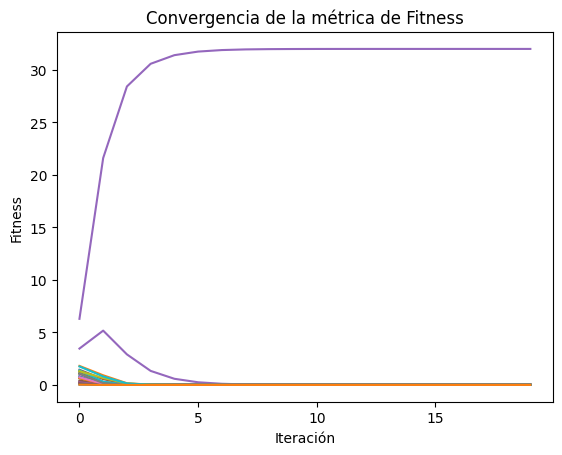

In [25]:
N = 20
Fseries = []
for iteration in range(N):
    F, Q = FitnessComplexity(Mcp, iteration)
    Fseries.append(F)
Fseries = np.array(Fseries)

# Graficar la evolución de la métrica de Fitness a lo largo de las iteraciones
fig, ax = plt.subplots(1, 1)
plt.plot(Fseries)
plt.xlabel('Iteración')
plt.ylabel('Fitness')
plt.xticks(range(0, N, 5), range(0, N, 5))
plt.title("Convergencia de la métrica de Fitness")
plt.show()

*Visualización de Fitness y Complejidad*

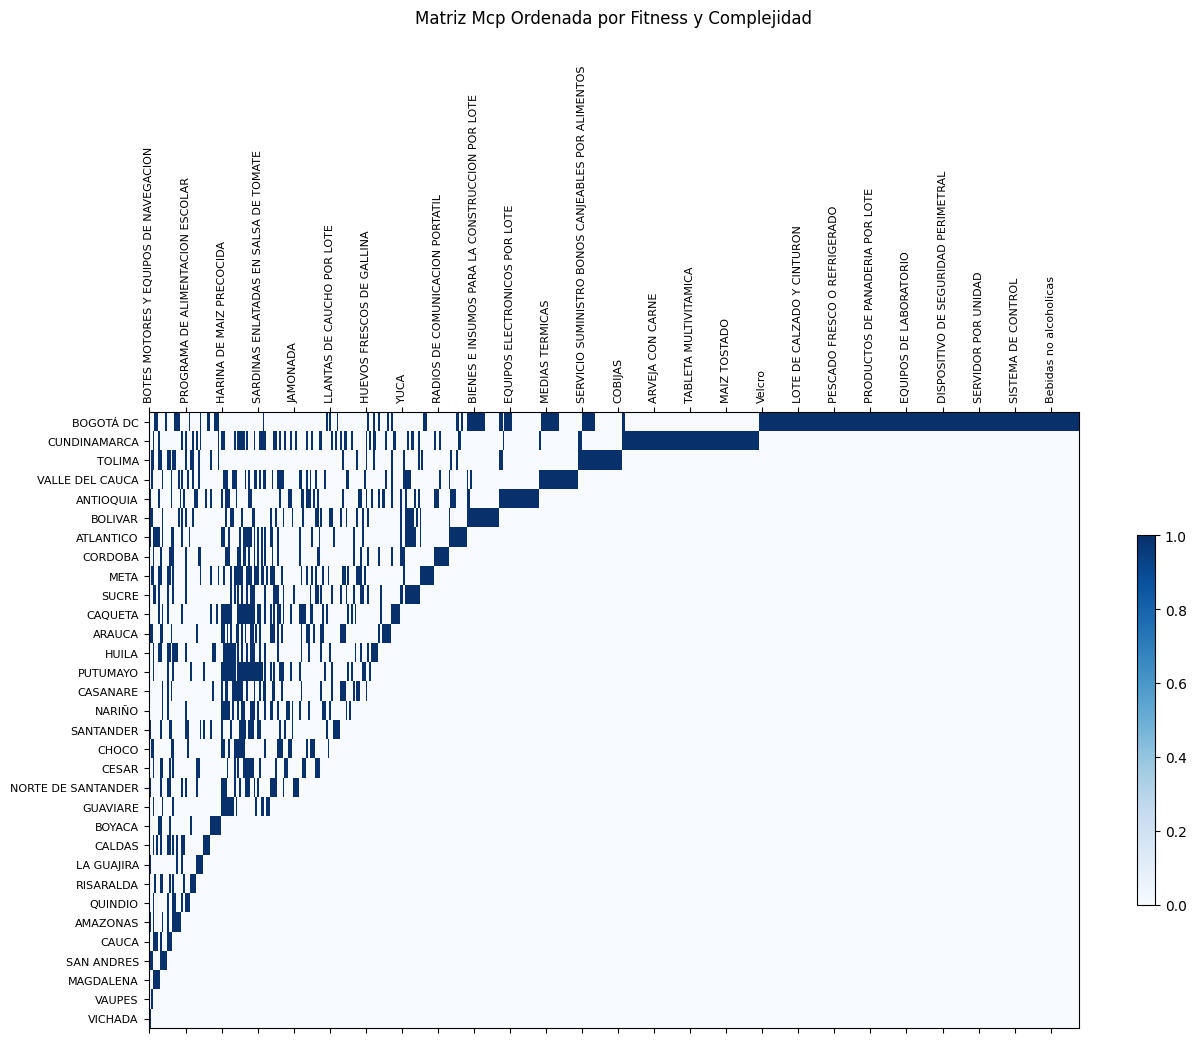

In [29]:
# Re-calcular Fitness (F) y Complejidad (Q) usando la matriz actual Mcp del dataset
F, Q = FitnessComplexity(Mcp, max_iterations=10)

# Ordenar los departamentos por sus niveles finales de Fitness de mayor a menor
order_countries = np.argsort(F)[::-1]

# Ordenar los productos por su nivel de complejidad de menor a mayor
order_products = np.argsort(Q)

# Re-estructurar la matriz ordenada para la visualización triangular
ordered_Mcp = np.zeros(np.shape(Mcp))
for c_idx in range(len(order_countries)):
    for p_idx in range(len(order_products)):
        ordered_Mcp[c_idx, p_idx] = Mcp[order_countries[c_idx], order_products[p_idx]]

# Graficar la estructura de la matriz ordenada usando ejes explícitos
fig = plt.figure(figsize=(15, 8))
ax = fig.add_subplot(111)
im = ax.matshow(ordered_Mcp, cmap='Blues', aspect='auto')

# Ajustar las etiquetas y ticks del eje Y
ax.set_yticks(range(R))
ax.set_yticklabels([departamento_ubicacion[i] for i in order_countries], fontsize=8)

# Ajustar las etiquetas y ticks del eje X
ax.set_xticks(range(0, C, 20))
ax.set_xticklabels([desc_subyacente[order_products[i]] for i in range(0, C, 20)], rotation=90, fontsize=8)

plt.title("Matriz Mcp Ordenada por Fitness y Complejidad", pad=30, fontsize=12)
fig.colorbar(im, ax=ax, shrink=0.6)
plt.show()

---

# 3. Relación (Relatedness) entre Actividades - *Visualización de la Red*

---

Visualizar y analizar la relación (relatedness) entre las actividades económicas. • Proporcionar una representación gráfica (por ejemplo, un diagrama de red o mapa de calor) que ilustre las conexiones entre los diferentes sectores.

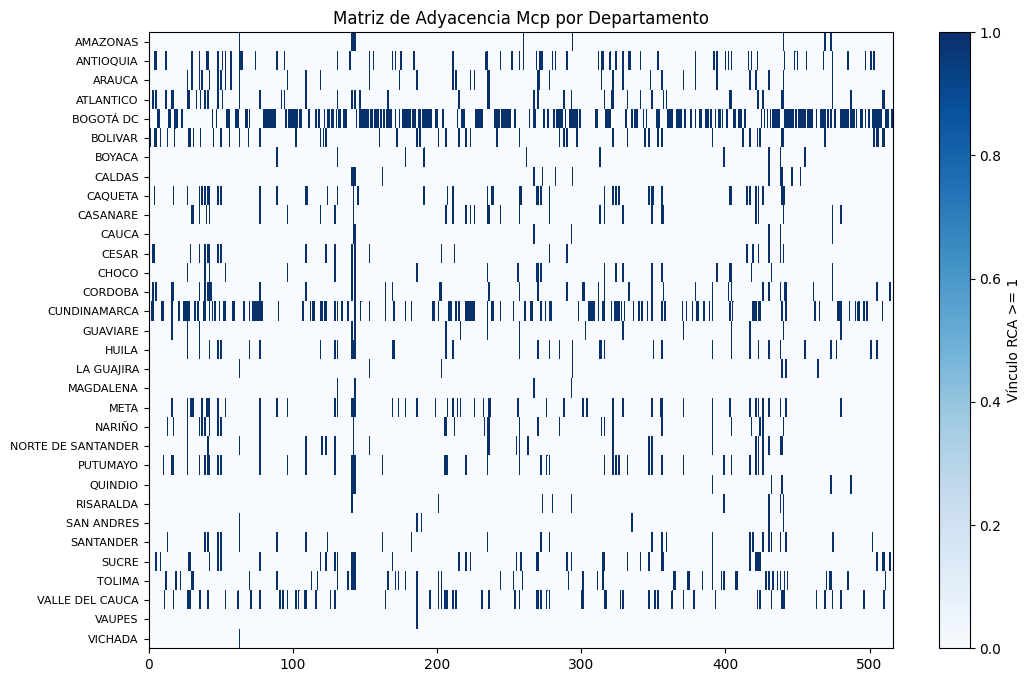

In [31]:
# Visualizar la matriz binaria Mcp original como una matriz de adyacencia

plt.figure(figsize=(12, 8))
plt.pcolor(Mcp, cmap='Blues')
plt.gca().invert_yaxis() # Invertir el eje Y para tener la primera fila en la parte superior
plt.yticks([i+0.5 for i in range(len(departamento_ubicacion))], departamento_ubicacion, fontsize=8)
plt.title("Matriz de Adyacencia Mcp por Departamento")
plt.colorbar(label="Vínculo RCA >= 1")
plt.show()

*Relación - Ejercicios prácticos de proximidad y afinidad con el Fitness*

In [32]:
# Calcular las co-ocurrencias entre productos

Jpp = Mcp.transpose().dot(Mcp)
print("Matriz de Co-ocurrencias de Productos (Jpp):")
print(Jpp)

Matriz de Co-ocurrencias de Productos (Jpp):
[[2 0 0 ... 1 0 1]
 [0 1 0 ... 0 0 0]
 [0 0 1 ... 0 0 0]
 ...
 [1 0 0 ... 1 0 1]
 [0 0 0 ... 0 2 0]
 [1 0 0 ... 1 0 1]]


In [33]:
# Función para calcular la proximidad en el Espacio del Producto (Product Space)
def ProductSpace(Mcp):
    Jpp = Mcp.transpose().dot(Mcp)

    ubiquity = Mcp.sum(0)
    ubiMat = np.tile(ubiquity, [Mcp.shape[1], 1])
    ubiMax = np.maximum(ubiMat, np.transpose(ubiMat)).astype(float)

    np.divide(np.ones_like(ubiMax, dtype=float), ubiMax, out=ubiMax, where=ubiMax != 0)
    return np.multiply(Jpp, ubiMax)

# Función para calcular la Taxonomía basada en la similitud de actividades
def Taxonomy(Mcp):
    diversification = Mcp.sum(1)
    ubiquity = Mcp.sum(0)

    Jpp = Mcp.transpose().dot(np.diag(1 / diversification).dot(Mcp))

    ubiMat = np.tile(ubiquity, [Mcp.shape[1], 1]).astype(float)
    ubiMax = np.maximum(ubiMat, np.transpose(ubiMat)).astype(float)

    np.divide(np.ones_like(ubiMax, dtype=float), ubiMax, out=ubiMax, where=ubiMax != 0)
    return np.multiply(Jpp, ubiMax)

# Función para calcular la Matriz de Asistencia (que no es simétrica)
def AssistMatrix(Mcp):
    diversification = Mcp.sum(1)
    ubiquity = Mcp.sum(0)

    Jpp = Mcp.transpose().dot(np.diag(1 / diversification).dot(Mcp))

    ubiMat = np.tile(ubiquity, [Mcp.shape[1], 1]).astype('float')

    np.divide(np.ones_like(ubiMat, dtype=float), ubiMat, out=ubiMat, where=ubiMat != 0)

    return np.multiply(Jpp, ubiMat)

In [34]:
# Imprimir la relación (proximidad) entre las primeras 4 actividades/productos
print("Matriz de Proximidad en el Espacio del Producto (Primeros 4x4):")
print(ProductSpace(Mcp)[:4, :4])

print("\nMatriz de Taxonomía (Primeros 4x4):")
print(Taxonomy(Mcp)[:4, :4])

# Notar cómo la Matriz de Asistencia resultante no es simétrica
print("\nMatriz de Asistencia (Primeros 4x4, no simétrica):")
print(AssistMatrix(Mcp)[:4, :4])

Matriz de Proximidad en el Espacio del Producto (Primeros 4x4):
[[1.   0.   0.   0.  ]
 [0.   1.   0.   0.  ]
 [0.   0.   1.   0.25]
 [0.   0.   0.25 1.  ]]

Matriz de Taxonomía (Primeros 4x4):
[[0.00954602 0.         0.         0.        ]
 [0.         0.01818182 0.         0.        ]
 [0.         0.         0.00757576 0.00189394]
 [0.         0.         0.00189394 0.0229915 ]]

Matriz de Asistencia (Primeros 4x4, no simétrica):
[[0.00954602 0.         0.         0.        ]
 [0.         0.01818182 0.         0.        ]
 [0.         0.         0.00757576 0.00189394]
 [0.         0.         0.00757576 0.0229915 ]]


In [38]:
# 1. ASIGNACIÓN DE VARIABLES DE COMPLEJIDAD (Sustituye por tus variables reales en el análisis final)
# Se asume que ECI y Fitness ya han sido calculados para los países/departamentos correspondientes
# En este caso ilustrativo se usan los resultados de las operaciones teóricas anteriores

# -------------------------------------------------------------------------
# 2. CÁLCULO DE COMPLEJIDAD ECONÓMICA (Establecer Dataframe para graficar)
# -------------------------------------------------------------------------

# Para corregir el error de la función FitnessComplexity no serializable, extraemos las variables correctas
# Usamos los valores calculados de Fitness F y ECI para los países de ejemplo
# Nota: F y ECI deben estar definidos como arreglos unidimensionales
ds_resultados = pd.DataFrame(
    {
        "departamento": departamento_ubicacion,
        "ECI": ECI,
        "Fitness": F,
    }
).dropna()

# -------------------------------------------------------------------------
# 3. GENERACIÓN DEL GRÁFICO DE DISPERSIÓN (Plotly)
# -------------------------------------------------------------------------

fig = px.scatter(
    ds_resultados,
    x="ECI",
    y="Fitness",
    text="departamento",  # Corregido: Se usa 'departamento' en lugar del inexistente 'countries'
    hover_name="departamento",  # Corregido: Se usa 'departamento' en lugar del inexistente 'countries'
    title="Relación entre ECI (Método Autovalores) y Fitness",
    labels={
        "ECI": "Índice de Complejidad Económica (ECI)",
        "Fitness": "Índice de Fitness",
    },
    template="plotly_white",
)

# Ajustes estéticos para que el texto no se amontone
fig.update_traces(textposition="top center", marker=dict(size=12, color="lightseagreen"))

# Mostrar gráfico
fig.show()

In [39]:
# ── Last cell: export variables + diversificación & ubicuidad + datos (with RCA, PCI, ECI) ──
from datetime import datetime
import openpyxl
import pandas as pd
import numpy as np

xl.close()   # release the Excel file opened with pd.ExcelFile

NOMBRE_HOJA = "Div_Ubicuidad"
anio = list(mcp_matrices_by_year.keys())[-1]
fecha_export = datetime.now().strftime("%Y-%m-%d %H:%M")

umbral = 0.1 # Aseguramos que la variable umbral esté definida localmente

# 0) Calculations (done once, reused below)
diversificacion = mcp_matrix.sum(axis=1)   # kd: products each department exports with RCA >= 1
ubicuidad       = mcp_matrix.sum(axis=0)   # kp: departments exporting each product with RCA >= 1

# 1) fecha_pago from the same year sheet used to build mcp_matrix
df_year = sheets_data[anio].copy()
if "fecha_pago" not in df_year.columns:
    raise KeyError(f"No existe 'fecha_pago' en la hoja '{anio}'. Columnas: {df_year.columns.tolist()}")
df_year["fecha_pago"] = pd.to_datetime(df_year["fecha_pago"], errors="coerce")

fecha_min = df_year["fecha_pago"].min()
fecha_max = df_year["fecha_pago"].max()

fechas_dep = (df_year.groupby("departamento_ubicacion")["fecha_pago"]
              .agg(["min", "max"]).reindex(mcp_matrix.index))
fechas_prod = (df_year.groupby("desc_subyacente")["fecha_pago"]
               .agg(["min", "max"]).reindex(mcp_matrix.columns))

# Obtener ECI y PCI (Complejidad Q) de forma dinámica usando el Método de Reflexiones
kc_dyn, kp_dyn = MethodOfReflections(mcp_matrix.values, max_iterations=10)

# 2) Variables used
df_variables = pd.DataFrame([
    ["Fecha de exportación",              fecha_export],
    ["Año de los datos (matriz)",         anio],
    ["fecha_pago mínima",                 fecha_min.strftime("%Y-%m-%d") if pd.notnull(fecha_min) else "N/A"],
    ["fecha_pago máxima",                 fecha_max.strftime("%Y-%m-%d") if pd.notnull(fecha_max) else "N/A"],
    ["Archivo fuente (BASE_DATOS16_25)",  str(BASE_DATOS16_25)],
    ["Hojas leídas (años)",               ", ".join(map(str, sheets_data.keys()))],
    ["Columna fila (departamento)",       "departamento_ubicacion"],
    ["Columna columna (producto)",        "desc_subyacente"],
    ["Columna valor",                     "valor_negocio"],
    ["Columna fecha",                     "fecha_pago"],
    ["Criterio matriz binaria Mcp",       "RCA >= 1"],
    ["Departamentos (R)",                 R],
    ["Productos (C)",                     C],
    ["Iteraciones Método de Reflexiones", 10],
    ["Umbral red de productos",           umbral],
], columns=["Variable", "Valor"])

# 3) Diversificación (+ ECI, Fitness, fecha_pago) per department
df_div = pd.DataFrame({
    "Año":                  anio,
    "Departamento":         mcp_matrix.index,
    "Diversificación":      diversificacion.values,
    "ECI":                  kc_dyn,
    "Fitness":              F,
    "fecha_pago (primera)": fechas_dep["min"].values,
    "fecha_pago (última)":  fechas_dep["max"].values,
}).sort_values("Diversificación", ascending=False)

# 4) Ubicuidad (+ PCI, Complejidad, fecha_pago) per product
df_ubi = pd.DataFrame({
    "Año":                  anio,
    "Producto":             mcp_matrix.columns,
    "Ubicuidad":            ubicuidad.values,
    "PCI":                  kp_dyn,
    "Complejidad":          Q,
    "fecha_pago (primera)": fechas_prod["min"].values,
    "fecha_pago (última)":  fechas_prod["max"].values,
}).sort_values("Ubicuidad", ascending=False)

# 5) Raw data used, attaching RCA, ECI (depto) and PCI (product) dynamically
cols_datos = ["departamento_ubicacion", "desc_subyacente", "fecha_pago", "valor_negocio"]
df_datos = df_year[cols_datos].copy()

# Mapeos de métricas para unirlas directamente con cada fila del dataset
eci_map = pd.Series(kc_dyn, index=mcp_matrix.index)
pci_map = pd.Series(kp_dyn, index=mcp_matrix.columns)

df_datos["Diversificación (depto)"] = df_datos["departamento_ubicacion"].map(diversificacion)
df_datos["Ubicuidad (producto)"]    = df_datos["desc_subyacente"].map(ubicuidad)
df_datos["ECI (depto)"]             = df_datos["departamento_ubicacion"].map(eci_map)
df_datos["PCI (producto)"]          = df_datos["desc_subyacente"].map(pci_map)

# Adición del valor real RCA correspondiente a cada fila (Departamento, Producto)
rca_unstacked = rca_matrix.stack().reset_index()
rca_unstacked.columns = ["departamento_ubicacion", "desc_subyacente", "RCA"]
df_datos = pd.merge(df_datos, rca_unstacked, on=["departamento_ubicacion", "desc_subyacente"], how="left")

# 6a) Remove the old sheet so reruns start clean
wb = openpyxl.load_workbook(BASE_DATOS16_25)
if NOMBRE_HOJA in wb.sheetnames:
    del wb[NOMBRE_HOJA]
wb.save(BASE_DATOS16_25)
wb.close()

# 6b) Write all blocks to the same sheet ("overlay" doesn't wipe earlier blocks)
with pd.ExcelWriter(BASE_DATOS16_25, engine="openpyxl", mode="a",
                    if_sheet_exists="overlay",
                    date_format="YYYY-MM-DD", datetime_format="YYYY-MM-DD") as writer:
    df_variables.to_excel(writer, sheet_name=NOMBRE_HOJA, index=False, startcol=0)   # A:B
    df_div.to_excel(writer, sheet_name=NOMBRE_HOJA, index=False, startcol=4)         # E:K
    df_ubi.to_excel(writer, sheet_name=NOMBRE_HOJA, index=False, startcol=12)        # M:R
    df_datos.to_excel(writer, sheet_name=NOMBRE_HOJA, index=False, startcol=20)      # U:AA

    ws = writer.sheets[NOMBRE_HOJA]
    anchos = {"A": 34, "B": 40,
              "E": 8, "F": 26, "G": 16, "H": 12, "I": 12, "J": 20, "K": 20,
              "M": 8, "N": 45, "O": 12, "P": 14, "Q": 20, "R": 20,
              "U": 28, "V": 28, "W": 14, "X": 16, "Y": 24, "Z": 22, "AA": 12}
    for col, w in anchos.items():
         ws.column_dimensions[col].width = w

print(f"Hoja '{NOMBRE_HOJA}' escrita exitosamente en: {BASE_DATOS16_25} (año {anio}, {fecha_export})")

Hoja 'Div_Ubicuidad' escrita exitosamente en: /content/drive/MyDrive/BMC-Datalab/Muestra_datos_MCP_MERCOP_2016-2025.xlsx (año Div_Ubicuidad, 2026-11-01 20:34)


In [40]:
import openpyxl
wb = openpyxl.load_workbook(BASE_DATOS16_25, read_only=True)
print(wb.sheetnames)   # 'Div_Ubicuidad' should appear here

['Export', 'Div_Ubicuidad']


In [41]:
from google.colab import files
files.download(str(BASE_DATOS16_25))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>